Fitted parameters: mu = 2.8815704790214367, sigma = 1.5687330231607999, lambda = 12.325903671379432, A = -1.4612283385699025


/var/folders/4b/vszk241x6rzfp13z0lgyr3pc0000gn/T/ipykernel_25073/70856698.py:43: OptimizeWarning: Covariance of the parameters could not be estimated
  var, cov = opt.curve_fit(f, bin_centers, hist, p0=[mu, sigma, 1, 0.5]);
/var/folders/4b/vszk241x6rzfp13z0lgyr3pc0000gn/T/ipykernel_25073/70856698.py:41: RuntimeWarning: divide by zero encountered in divide
  return len(positive_beers) *bin_width * (A*lam*np.exp(-lam*x) + (1-A)*1/(x*sigma*np.sqrt(2*np.pi)) * np.exp(-((np.log(x)-mu)**2 / 2*sigma**2)))
/var/folders/4b/vszk241x6rzfp13z0lgyr3pc0000gn/T/ipykernel_25073/70856698.py:41: RuntimeWarning: divide by zero encountered in log
  return len(positive_beers) *bin_width * (A*lam*np.exp(-lam*x) + (1-A)*1/(x*sigma*np.sqrt(2*np.pi)) * np.exp(-((np.log(x)-mu)**2 / 2*sigma**2)))
/var/folders/4b/vszk241x6rzfp13z0lgyr3pc0000gn/T/ipykernel_25073/70856698.py:41: RuntimeWarning: invalid value encountered in multiply
  return len(positive_beers) *bin_width * (A*lam*np.exp(-lam*x) + (1-A)*1/(x*sigma*n

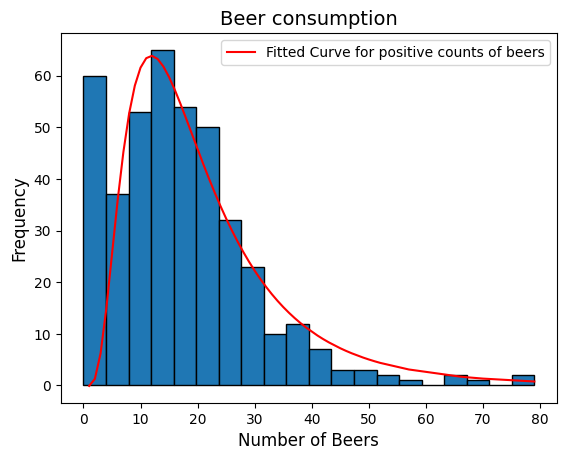

In [111]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.optimize as opt

streg1 = pd.read_csv('stregliste1.csv', delimiter=',', header=0, dtype=float)
beers1 = streg1[streg1.columns[0:5]].sum(axis=1)

streg2 = pd.read_csv('stregliste2.csv', delimiter=',', header=0, dtype=float)
beers2 = streg2[streg2.columns[0:5]].sum(axis=1)

streg3 = pd.read_csv('stregliste3.csv', delimiter=',', header=0, dtype=float)
beers3 = streg3[streg3.columns[0:5]].sum(axis=1)

streg4 = pd.read_csv('stregliste4.csv', delimiter=',', header=0, dtype=float)
beers4 = streg4[streg4.columns[0:5]].sum(axis=1)

beers_tot = np.concatenate((beers1, beers2, beers3, beers4))

bins = round(np.sqrt(len(beers_tot)))

positive_beers = beers_tot[beers_tot > 0] #log(0) not defined

plt.hist(beers_tot, bins=bins, edgecolor='black')
plt.xlabel('Number of Beers', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.title('Beer consumption', fontsize=14)


hist, bin_edges = np.histogram(positive_beers, bins=bins)

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2


mu = np.mean(np.log(positive_beers))
sigma = np.std(np.log(positive_beers))
bin_width = bin_edges[1] - bin_edges[0]


def f(x, mu, sigma, lam, A):
    return len(positive_beers) *bin_width * (A*lam*np.exp(-lam*x) + (1-A)*1/(x*sigma*np.sqrt(2*np.pi)) * np.exp(-((np.log(x)-mu)**2 / 2*sigma**2)))

var, cov = opt.curve_fit(f, bin_centers, hist, p0=[mu, sigma, 1, 0.5]);

print(f"Fitted parameters: mu = {var[0]}, sigma = {var[1]}, lambda = {var[2]}, A = {var[3]}")

plt.plot(np.sort(beers_tot), f(np.sort(beers_tot), *var), color='red', label='Fitted Curve for positive counts of beers');
plt.legend();
plt.show();


